# 2º Trabalho de Fundamentos de IA — Etapa 4: Aprendizado Probabilístico e EM
**Domínio:** Educação (SAEB 2021/2023 + Censo 2010) · **IComp/UFAM** · Prof. Edjard Mota

Esta etapa cobre as 6 tarefas do enunciado, com tudo implementado **do zero em numpy** (o scikit-learn só aparece para *conferir* as implementações):

1. **MLE** do parâmetro θ de uma Bernoulli
2. **MAP** com prior Beta(2,2)
3. **Naive Bayes** do zero para a classificação da Etapa 1 (`ALVO_MELHORA`), treino e teste
4. **Variável oculta Z** (2 ou 3 componentes) e **EM** para inferi-la
5. Gráfico da **log-verossimilhança** ao longo das iterações
6. Comparação: **Naive Bayes puro × Naive Bayes com EM**

> Mesmo conjunto das Etapas 1–3 (3.519 exemplos: município × dependência × localização), **mesmas 5 partições** de validação cruzada agrupadas por município (nenhum município aparece em treino e teste ao mesmo tempo) e os mesmos 5 atributos categóricos da Etapa 1. O alvo mede **associação**, não efeito causal do Novo Ensino Médio.

## 0. Configuração, dados e partições

In [1]:
import io, gzip, base64, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
pd.set_option('display.width', 160, 'display.max_columns', 30)

# Conjunto das Etapas 1-3 (SAEB 2021 + SAEB 2023 + IDHM_R do Censo 2010), já filtrado e cruzado, embutido para dispensar uploads.
EMBUTIDO = "..."
df = pd.read_csv(io.StringIO(gzip.decompress(base64.b64decode(EMBUTIDO)).decode()))

# --- mesmo alvo e mesmas faixas da Etapa 1 ---
df['ALVO_MELHORA'] = (df.MEDIA_12_MT_2023 > df.MEDIA_12_MT_2021).astype(int)
df['FAIXA_MEDIA_2021'] = pd.cut(df.MEDIA_12_MT_2021, [0, 250, 265, 280, 1000], right=False,
                                labels=['<250', '250-265', '265-280', '>=280']).astype(str)
df['FAIXA_IDHM_R'] = pd.cut(df.IDHM_R, [0, .5, .6, .7, .8, 2], right=False,
                            labels=['muito baixo', 'baixo', 'medio', 'alto', 'muito alto']).astype(str)
df['CO_UF'] = df.CO_UF.astype(str)

ATTRS = ['CO_UF', 'DEPENDENCIA_ADM', 'LOCALIZACAO', 'FAIXA_MEDIA_2021', 'FAIXA_IDHM_R']
TARGET = 'ALVO_MELHORA'
y, groups = df[TARGET].values, df.CO_MUNICIPIO.values

# Naive Bayes categórico trabalha com inteiros 0..V-1: codificamos cada atributo (a ordem das categorias é só rótulo)
cod = {a_: pd.factorize(df[a_], sort=True) for a_ in ATTRS}
X = np.column_stack([cod[a_][0] for a_ in ATTRS])
N_VALS = [len(cod[a_][1]) for a_ in ATTRS]
CATS = {a_: list(cod[a_][1]) for a_ in ATTRS}
print(f'{len(df)} exemplos | atributos e nº de valores: {dict(zip(ATTRS, N_VALS))} | P(melhora) = {y.mean():.3f}')

3519 exemplos | atributos e nº de valores: {'CO_UF': 27, 'DEPENDENCIA_ADM': 3, 'LOCALIZACAO': 2, 'FAIXA_MEDIA_2021': 4, 'FAIXA_IDHM_R': 5} | P(melhora) = 0.631


In [2]:
def kfold_por_grupo(y, grupos, k=5, seed=SEED):
    # 5-fold agrupado por município (cada município inteiro em UMA partição), balanceando tamanho e proporção da classe 1
    # (mesma função das Etapas 1 e 2)
    rng = np.random.RandomState(seed); y = np.asarray(y); grupos = np.asarray(grupos)
    ids = pd.unique(grupos); rng.shuffle(ids)
    info = pd.DataFrame({'g': grupos, 'y': y}).groupby('g').y.agg(['size', 'sum']).loc[ids]
    info = info.sort_values('size', ascending=False, kind='stable')
    tam, pos, dest, p1 = np.zeros(k), np.zeros(k), {}, y.mean()
    for g, (n, s_) in info.iterrows():
        f = min(range(k), key=lambda j: (tam[j], pos[j] - p1 * tam[j]))
        dest[g] = f; tam[f] += n; pos[f] += s_
    fold = np.array([dest[g] for g in grupos])
    return [(np.where(fold != j)[0], np.where(fold == j)[0]) for j in range(k)]

folds = kfold_por_grupo(y, groups)
print([(len(a), len(b)) for a, b in folds], '| municípios disjuntos entre treino e teste:',
      all(set(groups[a]).isdisjoint(groups[b]) for a, b in folds))
BASELINE = float(np.mean([(y[te] == np.bincount(y[tr]).argmax()).mean() for tr, te in folds]))
print(f'Baseline (sempre a classe majoritária), 5-fold: {BASELINE:.4f}')

[(2815, 704), (2815, 704), (2815, 704), (2816, 703), (2815, 704)] | municípios disjuntos entre treino e teste: True
Baseline (sempre a classe majoritária), 5-fold: 0.6311


### 0.1 Funções do zero (`em.py`)
As funções abaixo são as mesmas do script auxiliar `em.py` exigido na entrega. Ficam aqui dentro para o notebook rodar sozinho (Colab, sem upload). Só usam **numpy**.

In [3]:
# --- utilitário numérico: log(sum(exp(a))) estável ---
def logsumexp(a, axis=-1):
    m = a.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)

# --- Tarefas 1 e 2: MLE e MAP da Bernoulli ---
def loglik_bernoulli(theta, k, n):
    """log P(dados | theta) para k sucessos em n tentativas."""
    return k * np.log(theta) + (n - k) * np.log(1 - theta)


def mle_bernoulli(x):
    """theta_MLE = k/n (maximiza a log-verossimilhanca)."""
    x = np.asarray(x); return x.sum() / len(x)


def map_bernoulli(x, a=2.0, b=2.0):
    """theta_MAP com prior Beta(a,b): moda da posteriori Beta(a+k, b+n-k) = (k+a-1)/(n+a+b-2)."""
    x = np.asarray(x); k, n = x.sum(), len(x)
    return (k + a - 1) / (n + a + b - 2)

In [4]:
# --- Tarefa 3: Naive Bayes categórico ---
class NaiveBayesCat:
    """Naive Bayes para atributos categoricos codificados 0..V_j-1, com suavizacao de Laplace (alpha)."""

    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y, n_vals):
        X = np.asarray(X); y = np.asarray(y); self.classes_ = np.unique(y); self.n_vals_ = n_vals
        C = len(self.classes_)
        self.log_prior_ = np.log(np.bincount(y, minlength=C) / len(y))        # prior de classe = MLE (k/n)
        self.log_lik_ = []                                   # por atributo: array (C, V_j)
        for j, V in enumerate(n_vals):
            cont = np.zeros((C, V))
            for c in range(C):
                cont[c] = np.bincount(X[y == c, j], minlength=V)
            self.log_lik_.append(np.log((cont + self.alpha) / (cont.sum(1, keepdims=True) + self.alpha * V)))
        return self

    def log_joint(self, X):
        X = np.asarray(X); lj = np.tile(self.log_prior_, (len(X), 1))
        for j in range(X.shape[1]):
            lj += self.log_lik_[j][:, X[:, j]].T
        return lj

    def predict_proba(self, X):
        lj = self.log_joint(X); return np.exp(lj - logsumexp(lj, 1)[:, None])

    def predict(self, X):
        return self.log_joint(X).argmax(1)

In [5]:
# --- Tarefa 4: Naive Bayes com variável oculta Z, treinado por EM ---
class NaiveBayesEM:
    """Mistura de Naive Bayes por classe: P(C, Z, X) = P(C) P(Z|C) prod_j P(X_j | C, Z).
    C e observada no treino; Z (K componentes por classe) e OCULTA e inferida por EM.
    K=1 recupera exatamente o Naive Bayes puro. Dentro de cada (C,Z) os atributos sao independentes;
    marginalizando Z, deixam de ser (captura dependencias entre atributos dada a classe)."""

    def __init__(self, K=2, alpha=1.0, max_iter=200, tol=1e-6, n_init=10, seed=0):
        self.K, self.alpha, self.max_iter, self.tol, self.n_init, self.seed = K, alpha, max_iter, tol, n_init, seed

    # log P(x, z | c) para cada (n, k) usando os parametros dados
    def _log_xz(self, X, y, log_pi, log_th):
        lz = log_pi[y].copy()                                # (n, K)
        for j in range(X.shape[1]):
            lz += log_th[j][y, :, X[:, j]]                   # (n, K)
        return lz

    def _mstep(self, X, y, R):
        C, K = len(self.classes_), self.K
        pi = np.zeros((C, K)); th = [np.zeros((C, K, V)) for V in self.n_vals_]
        for c in range(C):
            Rc = R[y == c]; Xc = X[y == c]
            pi[c] = (Rc.sum(0) + self.alpha) / (Rc.sum() + self.alpha * K)
            for j, V in enumerate(self.n_vals_):
                for v in range(V):
                    th[j][c, :, v] = Rc[Xc[:, j] == v].sum(0)
                th[j][c] = (th[j][c] + self.alpha) / (th[j][c].sum(1, keepdims=True) + self.alpha * V)
        return np.log(pi), [np.log(t) for t in th]

    def _fit_once(self, X, y, rng):
        C, K = len(self.classes_), self.K
        R = rng.dirichlet(np.ones(K), size=len(X))           # inicializacao aleatoria das responsabilidades
        log_pi, log_th = self._mstep(X, y, R); hist, hist_map = [], []
        for it in range(self.max_iter):
            lz = self._log_xz(X, y, log_pi, log_th)           # E-step
            ll = logsumexp(lz, 1); R = np.exp(lz - ll[:, None])
            hist.append(float(ll.sum()))
            # objetivo MAP = log-verossimilhanca + alpha * soma(log parametros)  (prior de Dirichlet da suavizacao)
            pen = self.alpha * (log_pi.sum() + sum(t.sum() for t in log_th))
            hist_map.append(hist[-1] + float(pen))
            log_pi, log_th = self._mstep(X, y, R)             # M-step
            if it > 0 and abs(hist_map[-1] - hist_map[-2]) < self.tol * abs(hist_map[-2]): break
        return hist, hist_map, log_pi, log_th

    def fit(self, X, y, n_vals):
        X = np.asarray(X); y = np.asarray(y); self.classes_ = np.unique(y); self.n_vals_ = n_vals
        C = len(self.classes_)
        self.log_prior_ = np.log(np.bincount(y, minlength=C) / len(y))
        rng = np.random.RandomState(self.seed); best = None
        for _ in range(self.n_init):                          # varias inicializacoes: EM so acha otimo local
            h, hm, lp, lt = self._fit_once(X, y, rng)
            if best is None or hm[-1] > best[1][-1]: best = (h, hm, lp, lt)
        self.hist_, self.hist_map_, self.log_pi_, self.log_th_ = best
        return self

    def log_joint(self, X):
        X = np.asarray(X); out = np.zeros((len(X), len(self.classes_)))
        for c in range(len(self.classes_)):
            lz = self.log_pi_[c][None, :].repeat(len(X), 0)
            for j in range(X.shape[1]):
                lz += self.log_th_[j][c][:, X[:, j]].T
            out[:, c] = self.log_prior_[c] + logsumexp(lz, 1)   # marginaliza Z
        return out

    def predict_proba(self, X):
        lj = self.log_joint(X); return np.exp(lj - logsumexp(lj, 1)[:, None])

    def predict(self, X):
        return self.log_joint(X).argmax(1)

In [6]:
# --- EM gaussiano 1D: Listing 3 do enunciado ---
def gmm1d_em(x, K=2, max_iter=200, tol=1e-9, seed=0):
    """Mistura de K gaussianas 1D por EM. Retorna theta, mu, sigma (desvio) e historico da log-verossimilhanca."""
    x = np.asarray(x, float); N = len(x); rng = np.random.RandomState(seed)
    theta = np.ones(K) / K
    mu = rng.choice(x, K, replace=False); sigma = np.full(K, x.std())
    hist = []
    for it in range(max_iter):
        # E-step: r[i,k] proporcional a theta_k * N(x_i | mu_k, sigma_k)
        lp = (np.log(theta) - 0.5 * np.log(2 * np.pi * sigma ** 2)
              - 0.5 * ((x[:, None] - mu) / sigma) ** 2)
        ll = logsumexp(lp, 1); r = np.exp(lp - ll[:, None]); hist.append(float(ll.sum()))
        # M-step
        Nk = r.sum(0); theta = Nk / N
        mu = (r * x[:, None]).sum(0) / Nk
        sigma = np.sqrt((r * (x[:, None] - mu) ** 2).sum(0) / Nk)
        if it > 0 and abs(hist[-1] - hist[-2]) < tol * abs(hist[-2]): break
    return theta, mu, sigma, hist

## 1. MLE do parâmetro θ de uma Bernoulli
Seja $M_i\in\{0,1\}$ a indicação de que o município $i$ **melhorou** (`ALVO_MELHORA`), com $M_i\sim\text{Bernoulli}(\theta)$. Com $k$ sucessos em $n$ exemplos:

$$\log L(\theta)=k\log\theta+(n-k)\log(1-\theta)\;\;\Rightarrow\;\;\frac{d\log L}{d\theta}=\frac k\theta-\frac{n-k}{1-\theta}=0\;\;\Rightarrow\;\;\hat\theta_{MLE}=\frac kn$$

Conferimos a fórmula fechada maximizando numericamente $\log L$ numa grade fina de θ.

k = 2221 melhoras em n = 3519 exemplos
θ_MLE (fórmula fechada k/n) = 0.6311
θ que maximiza log L na grade = 0.6311   (|diferença| = 4.5e-05)


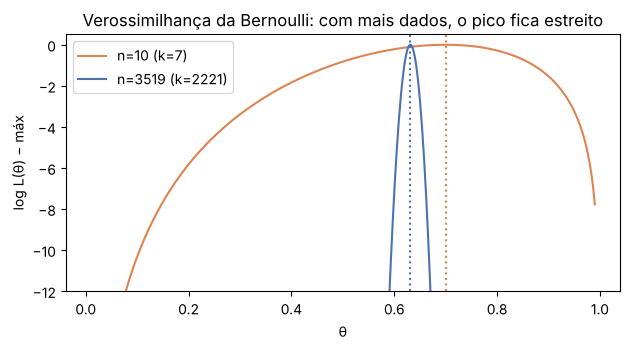

In [7]:
M = y; k, n = int(M.sum()), len(M)
theta_mle = mle_bernoulli(M)

grade = np.linspace(0.0005, 0.9995, 9991)
theta_grade = grade[np.argmax(loglik_bernoulli(grade, k, n))]
print(f'k = {k} melhoras em n = {n} exemplos')
print(f'θ_MLE (fórmula fechada k/n) = {theta_mle:.4f}')
print(f'θ que maximiza log L na grade = {theta_grade:.4f}   (|diferença| = {abs(theta_mle - theta_grade):.1e})')

# curva de log-verossimilhança relativa: amostra pequena (n=10) vs. conjunto todo
rng = np.random.RandomState(SEED); sub = rng.choice(M, 10, replace=False); k10 = int(sub.sum())
gr = np.linspace(0.01, 0.99, 500)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for kk, nn, lab, c in [(k10, 10, f'n=10 (k={k10})', '#dd8452'), (k, n, f'n={n} (k={k})', '#4c72b0')]:
    l = loglik_bernoulli(gr, kk, nn); ax.plot(gr, l - l.max(), label=lab, c=c)
    ax.axvline(kk / nn, ls=':', c=c)
ax.set_ylim(-12, 0.5); ax.set_xlabel('θ'); ax.set_ylabel('log L(θ) − máx'); ax.legend()
ax.set_title('Verossimilhança da Bernoulli: com mais dados, o pico fica estreito'); plt.tight_layout(); plt.show()

**Leitura:** o MLE é simplesmente a **frequência relativa** observada (63,1% dos pares melhoram). Com 10 exemplos a curva é larga (muitos θ explicam os dados quase igualmente); com 3.519 ela é um pico estreito. O MLE não guarda nenhuma noção dessa incerteza, o que motiva o MAP.

## 2. MAP com prior Beta(2,2)
Colocamos um prior $\theta\sim\text{Beta}(a,b)$ com $a=b=2$ (levemente centrado em 0,5, "como se já tivéssemos visto 1 sucesso e 1 fracasso"). Como Beta é **conjugada** da Bernoulli, a posteriori é $\text{Beta}(a+k,\,b+n-k)$ e o MAP é a sua moda:

$$\hat\theta_{MAP}=\frac{k+a-1}{n+a+b-2}=\frac{k+1}{n+2}\quad(a=b=2)$$

É a **suavização de Laplace** vista como MAP. Quando $n\to\infty$, MAP → MLE; com poucos dados, o prior puxa a estimativa para 0,5.

In [8]:
print(f'Conjunto todo (n={n}):  MLE = {mle_bernoulli(M):.4f} | MAP Beta(2,2) = {map_bernoulli(M, 2, 2):.4f}   (praticamente iguais)\n')

# Caso extremo: poucos dados
for xs in ([1, 1, 1], [1, 1, 1, 1, 1], [0, 0], [1, 0, 1, 1, 0, 1, 1, 1, 0, 1]):
    xs = np.array(xs)
    print(f'amostra {xs.tolist()!s:<32}  MLE = {mle_bernoulli(xs):.3f}   MAP = {map_bernoulli(xs, 2, 2):.3f}')

# Experimento: erro quadrático médio de cada estimador em subamostras (referência: θ* = frequência do conjunto todo)
REP = 2000; rng = np.random.RandomState(SEED); linhas = []
for nn in [3, 5, 10, 30, 100, 1000]:
    e_mle, e_map = [], []
    for _ in range(REP):
        s = rng.choice(M, nn, replace=False)
        e_mle.append((mle_bernoulli(s) - theta_mle) ** 2); e_map.append((map_bernoulli(s, 2, 2) - theta_mle) ** 2)
    linhas.append(dict(n=nn, EQM_MLE=np.mean(e_mle), EQM_MAP=np.mean(e_map), razao_MAP_sobre_MLE=np.mean(e_map) / np.mean(e_mle)))
tab_map = pd.DataFrame(linhas).set_index('n'); print(); print(tab_map.round(5).to_string())

Conjunto todo (n=3519):  MLE = 0.6311 | MAP Beta(2,2) = 0.6311   (praticamente iguais)

amostra [1, 1, 1]                         MLE = 1.000   MAP = 0.800
amostra [1, 1, 1, 1, 1]                   MLE = 1.000   MAP = 0.857
amostra [0, 0]                            MLE = 0.000   MAP = 0.250
amostra [1, 0, 1, 1, 0, 1, 1, 1, 0, 1]    MLE = 0.700   MAP = 0.667



      EQM_MLE  EQM_MAP  razao_MAP_sobre_MLE
n                                          
3     0.07639  0.03002              0.39298
5     0.04633  0.02491              0.53756
10    0.02361  0.01692              0.71645
30    0.00742  0.00659              0.88743
100   0.00230  0.00221              0.96121
1000  0.00017  0.00017              0.99739


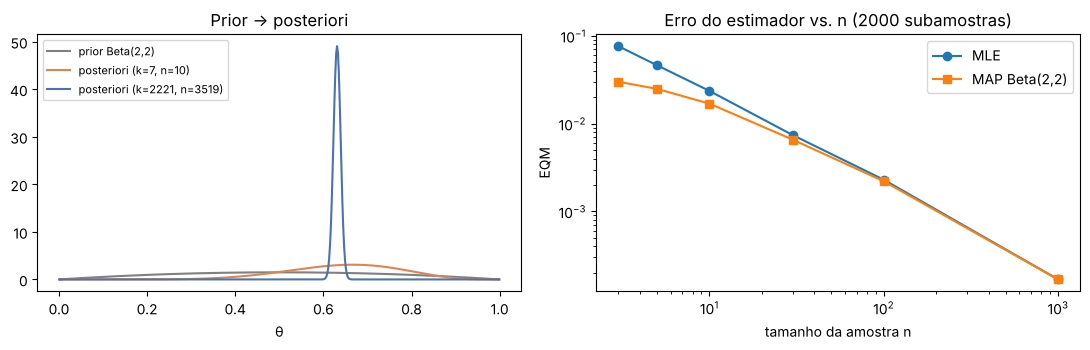

In [9]:
from scipy.stats import beta as beta_dist
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
th = np.linspace(0.001, 0.999, 500)
axs[0].plot(th, beta_dist.pdf(th, 2, 2), c='gray', label='prior Beta(2,2)')
for kk, nn, c in [(7, 10, '#dd8452'), (k, n, '#4c72b0')]:
    axs[0].plot(th, beta_dist.pdf(th, 2 + kk, 2 + nn - kk), c=c, label=f'posteriori (k={kk}, n={nn})')
axs[0].set_xlabel('θ'); axs[0].set_title('Prior → posteriori'); axs[0].legend(fontsize=8)
axs[1].plot(tab_map.index, tab_map.EQM_MLE, 'o-', label='MLE'); axs[1].plot(tab_map.index, tab_map.EQM_MAP, 's-', label='MAP Beta(2,2)')
axs[1].set_xscale('log'); axs[1].set_yscale('log'); axs[1].set_xlabel('tamanho da amostra n'); axs[1].set_ylabel('EQM'); axs[1].legend()
axs[1].set_title(f'Erro do estimador vs. n ({REP} subamostras)'); plt.tight_layout(); plt.show()

**Leitura:** com 3 sucessos em 3 tentativas o MLE diz θ = 1 (a Bernoulli "garante" sucesso), absurdo prático; o MAP dá 0,8. Nas subamostras, o MAP tem erro quadrático menor para n pequeno (encolhe a variância ao custo de um pequeno viés) e as duas estimativas **convergem** quando n cresce. Essa mesma ideia (somar pseudo-contagens) é a **suavização de Laplace** do Naive Bayes abaixo.

## 3. Naive Bayes do zero para `ALVO_MELHORA`
Para a classe $C\in\{0,1\}$ e os 5 atributos $X_1..X_5$ da Etapa 1:

$$P(C\mid x)\;\propto\;P(C)\prod_{j=1}^{5}P(X_j=x_j\mid C)$$

- $P(C)$: **MLE** (frequência da classe), como na seção 1.
- $P(X_j=v\mid C=c)=\dfrac{N_{c,v}+\alpha}{N_c+\alpha V_j}$: **MLE com suavização de Laplace** (equivale a MAP com prior de Dirichlet). Com $\alpha=0$ um valor nunca visto em treino numa classe zeraria o produto inteiro (ex.: uma UF com poucos municípios). Usamos $\alpha=1$.
- Trabalhamos em **log** (soma de logs) para evitar underflow.

Treinamos e testamos com as **mesmas 5 partições agrupadas** das Etapas 1 e 2.

In [10]:
def cv_modelo(make, X, y, folds, n_vals):
    acc_te, acc_tr = [], []; oof = np.zeros(len(y), int)
    for tr, te in folds:
        m = make().fit(X[tr], y[tr], n_vals)
        oof[te] = m.predict(X[te]); acc_te.append((oof[te] == y[te]).mean()); acc_tr.append((m.predict(X[tr]) == y[tr]).mean())
    return dict(te=np.array(acc_te), tr=np.array(acc_tr), oof=oof)

R_NB = cv_modelo(lambda: NaiveBayesCat(alpha=1.0), X, y, folds, N_VALS)
print('Acurácia por partição (teste):', R_NB['te'].round(3))
print(f"Naive Bayes puro:  treino = {R_NB['tr'].mean():.4f} | teste 5-fold = {R_NB['te'].mean():.4f} ± {R_NB['te'].std():.4f}   (baseline {BASELINE:.4f})")

# matriz de confusão com as predições fora-da-amostra de todas as partições
cm = pd.crosstab(pd.Series(y, name='real'), pd.Series(R_NB['oof'], name='previsto'))
prec, rec = cm.loc[1, 1] / cm[1].sum(), cm.loc[1, 1] / cm.loc[1].sum()
print('\nMatriz de confusão (predições fora-da-amostra):'); print(cm.to_string())
print(f'Classe 1 (melhorou): precisão = {prec:.3f} | recall = {rec:.3f}')

Acurácia por partição (teste): [0.723 0.689 0.692 0.718 0.737]
Naive Bayes puro:  treino = 0.7194 | teste 5-fold = 0.7119 ± 0.0187   (baseline 0.6311)

Matriz de confusão (predições fora-da-amostra):
previsto    0     1
real               
0         894   404
1         610  1611
Classe 1 (melhorou): precisão = 0.800 | recall = 0.725


In [11]:
# Conferência com o scikit-learn (CategoricalNB, mesmo alpha): as predições devem coincidir
from sklearn.naive_bayes import CategoricalNB
tr, te = folds[0]
sk_nb = CategoricalNB(alpha=1.0, min_categories=N_VALS).fit(X[tr], y[tr])
meu = NaiveBayesCat(1.0).fit(X[tr], y[tr], N_VALS)
print('Predições idênticas ao scikit-learn:', bool((sk_nb.predict(X[te]) == meu.predict(X[te])).all()),
      '| máx |ΔP(C|x)| =', f'{np.abs(sk_nb.predict_proba(X[te]) - meu.predict_proba(X[te])).max():.1e}')

# Efeito da suavização
print('\nEfeito do alpha (acurácia 5-fold):')
for a_ in [1e-6, 0.1, 1, 5, 20]:
    r_ = cv_modelo(lambda: NaiveBayesCat(alpha=a_), X, y, folds, N_VALS); print(f'  alpha = {a_:<7g} → {r_["te"].mean():.4f}')

# O que o modelo aprendeu: P(faixa da média inicial | classe) e P(classe)
nb_full = NaiveBayesCat(1.0).fit(X, y, N_VALS)
j = ATTRS.index('FAIXA_MEDIA_2021')
print('\nP(C):', np.exp(nb_full.log_prior_).round(3), '(0 = não melhorou, 1 = melhorou)')
print(pd.DataFrame(np.exp(nb_full.log_lik_[j]).T, index=CATS['FAIXA_MEDIA_2021'], columns=['P(faixa | C=0)', 'P(faixa | C=1)']).round(3).to_string())

Predições idênticas ao scikit-learn: True | máx |ΔP(C|x)| = 1.4e-15

Efeito do alpha (acurácia 5-fold):
  alpha = 1e-06   → 0.7113
  alpha = 0.1     → 0.7116
  alpha = 1       → 0.7119
  alpha = 5       → 0.7136
  alpha = 20      → 0.7150

P(C): [0.369 0.631] (0 = não melhorou, 1 = melhorou)
         P(faixa | C=0)  P(faixa | C=1)
250-265           0.155           0.326
265-280           0.402           0.246
<250              0.048           0.321
>=280             0.396           0.107


**Leitura:** o Naive Bayes fica na casa dos ~71% de acurácia de teste, **bem acima do baseline majoritário (63,1%)**, mas um pouco abaixo da árvore da Etapa 1 e da regressão logística da Etapa 2 (≈ 74%). A implementação própria coincide com o `CategoricalNB` do scikit-learn. O alvo praticamente "depende" de `FAIXA_MEDIA_2021` (regressão à média), e o modelo aprendeu isso (quem partiu de média baixa tem P(faixa|melhorou) alta). O ponto fraco é a suposição de **independência condicional**: na Etapa 3 vimos que `B` (média inicial baixa) e `I` (IDHM baixo) **não** são independentes dado o alvo. Isso é o que a variável oculta Z da próxima seção tenta contornar.

## 4. Variável oculta Z e o algoritmo EM
### 4.1 EM gaussiano 1D (Listing 3 do enunciado)
Antes de colocar Z dentro do Naive Bayes, rodamos o pseudocódigo do enunciado **literalmente**: mistura de $K=2$ gaussianas na variável contínua `IDHM_R` (IDH-M de renda, Censo 2010), com Z = "grupo latente" de cada município. Sem usar a região nem o alvo, o EM deve descobrir sozinho se existem perfis distintos de renda.

- **E-step:** $r_{ik}=\dfrac{\theta_k\,\mathcal N(x_i\mid\mu_k,\sigma_k)}{\sum_{k'}\theta_{k'}\,\mathcal N(x_i\mid\mu_{k'},\sigma_{k'})}$
- **M-step:** $N_k=\sum_i r_{ik}$, $\theta_k=N_k/N$, $\mu_k=\frac1{N_k}\sum_i r_{ik}x_i$, $\sigma_k^2=\frac1{N_k}\sum_i r_{ik}(x_i-\mu_k)^2$
- Pare quando a log-verossimilhança $\sum_i\log\sum_k\theta_k\mathcal N(x_i\mid\mu_k,\sigma_k)$ estabiliza.

In [12]:
x = df.IDHM_R.values

# EM é sensível à inicialização (só garante máximo LOCAL): 10 inicializações, ficamos com a melhor log-verossimilhança
fits = [gmm1d_em(x, K=2, seed=s, tol=1e-7, max_iter=500) for s in range(10)]
theta_g, mu_g, sg_g, hist_g = max(fits, key=lambda f: f[3][-1])
print(f'Convergiu em {len(hist_g)} iterações | log-verossimilhança final = {hist_g[-1]:.2f}')
print('Variação mínima entre iterações (≥ 0 ⇒ crescimento monotônico):', f'{np.diff(hist_g).min():.2e}')
print('Log-verossimilhança final por inicialização:', sorted(round(f[3][-1], 1) for f in fits))
for kk in range(2): print(f'  componente {kk}: θ = {theta_g[kk]:.3f} | μ = {mu_g[kk]:.3f} | σ = {sg_g[kk]:.3f}')

# conferência com scikit-learn (mesmo modelo, outra implementação)
from sklearn.mixture import GaussianMixture
gm = GaussianMixture(2, n_init=10, random_state=SEED, tol=1e-9, max_iter=500).fit(x.reshape(-1, 1))
print(f'scikit-learn GaussianMixture: log-verossimilhança = {gm.score(x.reshape(-1, 1)) * len(x):.2f}')

# o que Z significa em relação ao alvo?
lp = np.log(theta_g) - .5 * np.log(2 * np.pi * sg_g ** 2) - .5 * ((x[:, None] - mu_g) / sg_g) ** 2
Zhat = lp.argmax(1)
print('\nP(melhora | componente mais provável):')
nne = (pd.to_numeric(df.CO_UF) // 10).isin([1, 2]).values      # 1 = Norte ou Nordeste (a região NÃO entrou no EM)
print(pd.DataFrame({'n': np.bincount(Zhat), 'IDHM_R médio': [x[Zhat == kk].mean() for kk in range(2)],
                    '% Norte/Nordeste': [nne[Zhat == kk].mean() for kk in range(2)],
                    'média SAEB 2021': [df.MEDIA_12_MT_2021[Zhat == kk].mean() for kk in range(2)],
                    'P(melhora)': [y[Zhat == kk].mean() for kk in range(2)]}).round(3).to_string())

Convergiu em 49 iterações | log-verossimilhança final = 4105.67
Variação mínima entre iterações (≥ 0 ⇒ crescimento monotônico): 3.31e-04
Log-verossimilhança final por inicialização: [4105.7, 4105.7, 4105.7, 4105.7, 4105.7, 4105.7, 4105.7, 4105.7, 4105.7, 4105.7]
  componente 0: θ = 0.365 | μ = 0.559 | σ = 0.039
  componente 1: θ = 0.635 | μ = 0.698 | σ = 0.049


scikit-learn GaussianMixture: log-verossimilhança = 4105.67

P(melhora | componente mais provável):
      n  IDHM_R médio  % Norte/Nordeste  média SAEB 2021  P(melhora)
0  1298         0.557             0.858          253.787       0.787
1  2221         0.700             0.100          271.690       0.540


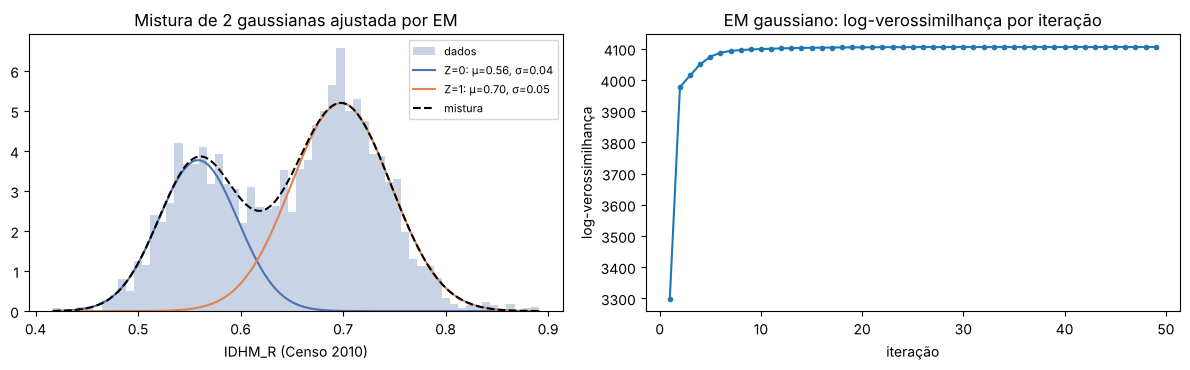

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].hist(x, bins=60, density=True, color='#c9d3e6', label='dados')
xx = np.linspace(x.min(), x.max(), 400)
dens = lambda kk: theta_g[kk] * np.exp(-.5 * ((xx - mu_g[kk]) / sg_g[kk]) ** 2) / (sg_g[kk] * np.sqrt(2 * np.pi))
for kk, c in zip(range(2), ['#4c72b0', '#dd8452']): axs[0].plot(xx, dens(kk), c=c, label=f'Z={kk}: μ={mu_g[kk]:.2f}, σ={sg_g[kk]:.2f}')
axs[0].plot(xx, dens(0) + dens(1), 'k--', label='mistura'); axs[0].set_xlabel('IDHM_R (Censo 2010)'); axs[0].legend(fontsize=8)
axs[0].set_title('Mistura de 2 gaussianas ajustada por EM')
axs[1].plot(range(1, len(hist_g) + 1), hist_g, 'o-', ms=3); axs[1].set_xlabel('iteração'); axs[1].set_ylabel('log-verossimilhança')
axs[1].set_title('EM gaussiano: log-verossimilhança por iteração'); plt.tight_layout(); plt.show()

### 4.2 Naive Bayes com variável oculta Z (EM)
Agora Z entra no classificador. Para cada classe $C$ há $K$ **sub-grupos latentes** $Z$ (por exemplo, "perfis" de municípios dentro dos que melhoraram), e os atributos são independentes **dado $(C,Z)$**:

$$P(C,Z,X)=P(C)\,P(Z\mid C)\prod_{j}P(X_j\mid C,Z)\qquad\Rightarrow\qquad P(C\mid x)\propto P(C)\sum_{z=1}^{K}P(z\mid C)\prod_j P(x_j\mid C,z)$$

Por que isso ajuda? Dentro de cada $(C,Z)$ a suposição de Naive Bayes continua valendo, mas **marginalizando Z** os atributos deixam de ser independentes dado $C$: o modelo consegue representar a dependência entre média inicial e IDHM que a Etapa 3 detectou. Com $K=1$ recupera-se exatamente o Naive Bayes puro.

Como $Z$ não é observada, usamos **EM** (aqui $C$ é observada, só $Z$ é oculta):
- **E-step:** $r_{ik}=P(Z=k\mid c_i,x_i)\propto P(k\mid c_i)\prod_j P(x_{ij}\mid c_i,k)$
- **M-step:** $P(k\mid c)=\dfrac{\sum_{i:c_i=c}r_{ik}+\alpha}{N_c+K\alpha}$ e $P(X_j=v\mid c,k)=\dfrac{\sum_{i:c_i=c,\,x_{ij}=v}r_{ik}+\alpha}{\sum_{i:c_i=c}r_{ik}+V_j\alpha}$ (contagens **esperadas** + suavização, igual ao Naive Bayes, mas com contagens ponderadas por $r_{ik}$).

Como o M-step usa suavização (MAP), o que o EM garante crescer monotonicamente é a log-verossimilhança **penalizada** (log-posteriori, com o prior de Dirichlet da suavização); a log-verossimilhança pura também é mostrada. 10 inicializações aleatórias, fica a melhor.

In [14]:
# Ajuste no conjunto todo (para ver a convergência e interpretar Z)
modelos_full = {K: NaiveBayesEM(K=K, alpha=1.0, n_init=10, seed=0).fit(X, y, N_VALS) for K in (2, 3)}
for K, m in modelos_full.items():
    hm, h = np.array(m.hist_map_), np.array(m.hist_)
    print(f'K={K}: convergiu em {len(hm)} iterações | log-verossimilhança {h[0]:.1f} → {h[-1]:.1f} | '
          f'menor variação do objetivo MAP = {np.diff(hm).min():.2e} (≥ 0 ⇒ monotônico) | '
          f'menor variação da log-verossimilhança pura = {np.diff(h).min():.2e}')

# Sanidade: K=1 deve reproduzir o Naive Bayes puro
m1 = NaiveBayesEM(K=1, alpha=1.0, n_init=1).fit(X, y, N_VALS)
print('\nK=1 (sem Z) idêntico ao Naive Bayes puro:', bool((m1.predict(X) == NaiveBayesCat(1.0).fit(X, y, N_VALS).predict(X)).all()))

K=2: convergiu em 26 iterações | log-verossimilhança -19754.9 → -18128.9 | menor variação do objetivo MAP = 1.17e-02 (≥ 0 ⇒ monotônico) | menor variação da log-verossimilhança pura = 5.28e-04
K=3: convergiu em 50 iterações | log-verossimilhança -19765.3 → -17837.0 | menor variação do objetivo MAP = 1.58e-02 (≥ 0 ⇒ monotônico) | menor variação da log-verossimilhança pura = -7.17e-03

K=1 (sem Z) idêntico ao Naive Bayes puro: True


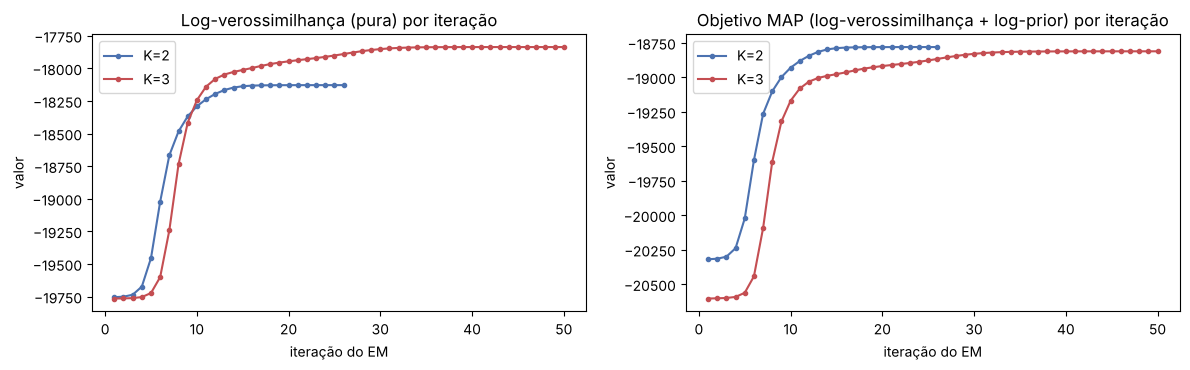

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for K, c in zip((2, 3), ['#4c72b0', '#c44e52']):
    m = modelos_full[K]
    axs[0].plot(range(1, len(m.hist_) + 1), m.hist_, 'o-', ms=3, c=c, label=f'K={K}')
    axs[1].plot(range(1, len(m.hist_map_) + 1), m.hist_map_, 'o-', ms=3, c=c, label=f'K={K}')
axs[0].set_title('Log-verossimilhança (pura) por iteração'); axs[1].set_title('Objetivo MAP (log-verossimilhança + log-prior) por iteração')
for ax in axs: ax.set_xlabel('iteração do EM'); ax.set_ylabel('valor'); ax.legend()
plt.tight_layout(); plt.show()

**Leitura:** as curvas **sobem rápido e estabilizam**; o objetivo MAP nunca decresce, como o EM garante. A log-verossimilhança pura sobe da mesma forma, mas pode ter quedas minúsculas (frações de unidade em ~18.000) porque a suavização do M-step otimiza o objetivo MAP, não a verossimilhança pura. O EM é sensível à inicialização e só garante máximo local, por isso usamos várias reinicializações.

In [16]:
# O que Z aprendeu? K=2: para cada classe e componente, P(Z|C) e a distribuição das faixas de média inicial e de IDHM
m2 = modelos_full[2]; linhas = []
for c in (0, 1):
    for kk in range(2):
        r = {'classe C': c, 'componente Z': kk, 'P(Z|C)': np.exp(m2.log_pi_[c, kk])}
        for a_ in ['FAIXA_MEDIA_2021', 'FAIXA_IDHM_R']:
            j = ATTRS.index(a_); p = np.exp(m2.log_th_[j][c, kk])
            r[f'{a_}: valor mais provável'] = f'{CATS[a_][p.argmax()]} ({p.max():.0%})'
        linhas.append(r)
print(pd.DataFrame(linhas).round(3).to_string(index=False))

# E as dependências? Compara dependência B-I dada a classe: o NB puro assume 0
print('\nDiferença P(B=1,I=1|C) − P(B=1|C)·P(I=1|C) com B = faixa de média inicial < 265 e I = IDHM < 0,6 (observada nos dados):')
for c in (0, 1):
    d = df[y == c]; Bc = (d.MEDIA_12_MT_2021 < 265); Ic = (d.IDHM_R < .6)
    print(f'  C={c}: {(Bc & Ic).mean() - Bc.mean() * Ic.mean():+.3f}   (o NB puro assume 0)')

 classe C  componente Z  P(Z|C) FAIXA_MEDIA_2021: valor mais provável FAIXA_IDHM_R: valor mais provável
        0             0   0.244                         265-280 (31%)                       baixo (73%)
        0             1   0.756                           >=280 (45%)                        alto (57%)
        1             0   0.485                            <250 (56%)                       baixo (76%)
        1             1   0.515                         265-280 (37%)                       medio (57%)

Diferença P(B=1,I=1|C) − P(B=1|C)·P(I=1|C) com B = faixa de média inicial < 265 e I = IDHM < 0,6 (observada nos dados):
  C=0: +0.038   (o NB puro assume 0)
  C=1: +0.079   (o NB puro assume 0)


## 5. Comparação: Naive Bayes puro × Naive Bayes com EM
Mesmas 5 partições agrupadas por município e mesmos atributos. $K=1$ é o NB puro; $K=2$ e $K=3$ são as versões com variável oculta. O EM é treinado **só com os dados de treino** de cada partição (inclusive as 10 inicializações aleatórias).

In [17]:
RES = {'Baseline majoritário': None, 'Naive Bayes puro (K=1)': R_NB}
for K in (2, 3):
    RES[f'Naive Bayes + EM (K={K})'] = cv_modelo(lambda: NaiveBayesEM(K=K, alpha=1.0, n_init=10, seed=0), X, y, folds, N_VALS)

def n_params(K): return sum(K * 2 * (V - 1) for V in N_VALS) + 2 * (K - 1) + 1   # parâmetros livres
linhas = [{'Modelo': 'Baseline majoritário', 'Acurácia treino': np.nan, 'Acurácia teste (5-fold)': BASELINE, 'Desvio entre folds': np.nan, 'Parâmetros livres': 1}]
for nome, r in list(RES.items())[1:]:
    K = 1 if 'puro' in nome else int(nome.split('=')[1][0])
    linhas.append({'Modelo': nome, 'Acurácia treino': r['tr'].mean(), 'Acurácia teste (5-fold)': r['te'].mean(),
                   'Desvio entre folds': r['te'].std(), 'Parâmetros livres': n_params(K)})
tab = pd.DataFrame(linhas).set_index('Modelo'); print(tab.round(4).to_string())

print('\nAcurácia de teste por partição:')
print(pd.DataFrame({n_: r['te'] for n_, r in list(RES.items())[1:]}).round(3).to_string())
print('\nDiferença pareada por partição (NB+EM − NB puro):')
for K in (2, 3):
    d = RES[f'Naive Bayes + EM (K={K})']['te'] - R_NB['te']
    print(f'  K={K}: {np.round(d, 3)} | média = {d.mean():+.4f} | melhora em {(d > 0).sum()}/5 partições')

                        Acurácia treino  Acurácia teste (5-fold)  Desvio entre folds  Parâmetros livres
Modelo                                                                                                 
Baseline majoritário                NaN                   0.6311                 NaN                  1
Naive Bayes puro (K=1)           0.7194                   0.7119              0.0187                 73
Naive Bayes + EM (K=2)           0.7385                   0.7261              0.0168                147
Naive Bayes + EM (K=3)           0.7401                   0.7343              0.0133                221

Acurácia de teste por partição:
   Naive Bayes puro (K=1)  Naive Bayes + EM (K=2)  Naive Bayes + EM (K=3)
0                   0.723                   0.729                   0.743
1                   0.689                   0.726                   0.724
2                   0.692                   0.695                   0.713
3                   0.718                   0.7

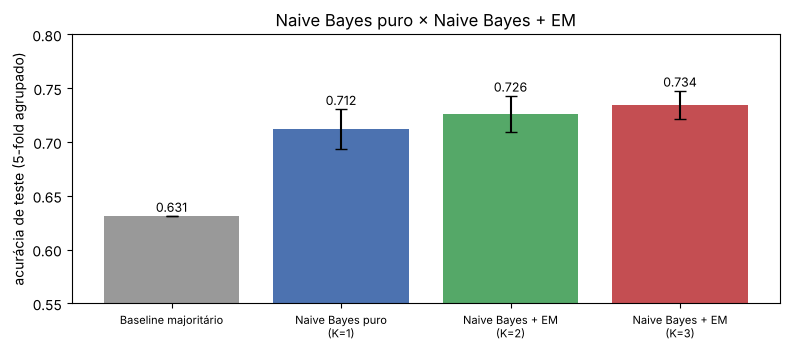

In [18]:
nomes = list(RES.keys()); medias = [BASELINE] + [RES[n_]['te'].mean() for n_ in nomes[1:]]; dps = [0] + [RES[n_]['te'].std() for n_ in nomes[1:]]
fig, ax = plt.subplots(figsize=(8, 3.6))
cores = ['#999999', '#4c72b0', '#55a868', '#c44e52']
ax.bar(range(len(nomes)), medias, yerr=dps, color=cores, capsize=4)
for i, m_ in enumerate(medias): ax.text(i, m_ + dps[i] + .004, f'{m_:.3f}', ha='center', fontsize=9)
ax.set_xticks(range(len(nomes))); ax.set_xticklabels([n_.replace(' (', '\n(') for n_ in nomes], fontsize=8)
ax.set_ylim(0.55, 0.80); ax.set_ylabel('acurácia de teste (5-fold agrupado)'); ax.set_title('Naive Bayes puro × Naive Bayes + EM')
plt.tight_layout(); plt.show()

## 6. Discussão e resumo

| Item | Resultado |
|---|---|
| MLE de θ = P(melhora) | 0,631 (= 2221/3519), confere com a maximização numérica |
| MAP Beta(2,2) | 0,631 no conjunto todo; com n pequeno encolhe para 0,5 e tem erro quadrático até ~60% menor (n=3) |
| Naive Bayes puro (5-fold agrupado) | **71,2%** ± 1,9 (baseline 63,1%); idêntico ao `CategoricalNB` do scikit-learn |
| Naive Bayes + EM, K=2 | **72,6%** ± 1,7 (+1,4 p.p.; melhora em 5/5 partições) |
| Naive Bayes + EM, K=3 | **73,4%** ± 1,3 (+2,3 p.p.; melhora em 5/5 partições) |
| Convergência do EM | monotônica; ~26 iterações (K=2) e ~50 (K=3) |

- **MLE × MAP:** o MLE é a frequência relativa e não expressa incerteza (3 sucessos em 3 tentativas ⇒ θ = 1). O MAP com Beta(2,2) equivale a somar uma pseudo-observação de cada resultado; ajuda quando há poucos dados e converge para o MLE quando n cresce. A mesma ideia sustenta a suavização de Laplace do Naive Bayes.
- **Naive Bayes puro:** ~11 pontos acima do baseline, mas ~2–3 pontos abaixo da árvore (≈ 73,9%) e da logística (≈ 74,1%) das Etapas 1 e 2. A causa mais provável é a suposição de independência condicional, que a Etapa 3 mostrou ser violada (média inicial baixa e IDHM baixo são correlacionados mesmo dado o alvo).
- **Com variável oculta Z:** o EM aprende, dentro de cada classe, subgrupos de municípios. Com K=2, em cada classe aparecem um perfil de **IDHM baixo** e outro de **IDHM médio/alto** (e médias iniciais diferentes), ou seja, Z absorve a dependência entre renda e desempenho inicial que o Naive Bayes puro ignora. Isso rendeu ganho pequeno, mas **consistente** (melhora em todas as 5 partições). Os modelos com Z têm mais parâmetros livres (73 → 147 → 221), e a acurácia de treino sobe pouco (71,9% → 74,0%), sem sinal forte de overfitting.
- **EM gaussiano (Listing 3):** sem usar o alvo nem a região, a mistura de 2 gaussianas em `IDHM_R` encontrou dois grupos (≈ 36% com IDHM médio 0,56, dos quais 86% são do Norte/Nordeste, e ≈ 64% com 0,70, só 10% N/NE). Todas as 10 inicializações chegaram à mesma log-verossimilhança (4105,67), igual à do `GaussianMixture` do scikit-learn.
- **Frente ao "gabarito" do enunciado** (NB puro 72–78%, NB+EM 80–86%): o NB puro (71,2%) fica um pouco abaixo da faixa e o NB+EM (72,6–73,4%) bem abaixo. Como nas Etapas 1 e 2, os valores do enunciado são genéricos; aqui o alvo compara duas medições ruidosas de médias municipais e só há 5 atributos categóricos grosseiros. Reportamos o que foi obtido. A curva de log-verossimilhança cresce monotonicamente e estabiliza em ~26 iterações (K=2), dentro da faixa de 15–30 do enunciado; com K=3 leva ~50.

**Limitações para o relatório**
1. A diferença entre NB puro e NB+EM (1,4 a 2,3 p.p.) é **menor que o desvio entre partições** (1,3 a 1,9 p.p.), embora tenha o mesmo sinal em todas as partições; é indício, não prova. As linhas de um mesmo município não são independentes (por isso o 5-fold é agrupado).
2. K=3 foi escolhido olhando o desempenho de teste; uma escolha rigorosa de K exigiria validação aninhada (ou BIC). K=2 é a versão "principal"; K=3 mostra a tendência.
3. EM só garante máximo **local**: usamos 10 inicializações e ficamos com a melhor. O rótulo dos componentes de Z é arbitrário (*label switching*); interpretamos Z olhando os parâmetros, não o número.
4. `CO_UF` tem 27 valores e domina o número de parâmetros; a regressão à média (Etapa 1) continua sendo a razão principal de `FAIXA_MEDIA_2021` prever o alvo, e nada aqui prova efeito do Novo Ensino Médio.
5. Próxima etapa: a Rede Bayesiana (Etapa 5) modela a dependência entre atributos **explicitamente** (arestas), em vez de escondê-la numa variável latente.


## 7. Exportar a tabela de métricas para o LaTeX

In [19]:
lat = tab.copy(); lat.index = [i.replace('%', r'\%') for i in lat.index]
print(lat.round(3).to_latex(float_format='%.3f', na_rep='--', caption='Etapa 4: Naive Bayes puro e com EM (5-fold agrupado por município).', label='tab:etapa4'))

\begin{table}
\caption{Etapa 4: Naive Bayes puro e com EM (5-fold agrupado por município).}
\label{tab:etapa4}
\begin{tabular}{lrrrr}
\toprule
 & Acurácia treino & Acurácia teste (5-fold) & Desvio entre folds & Parâmetros livres \\
\midrule
Baseline majoritário & -- & 0.631 & -- & 1 \\
Naive Bayes puro (K=1) & 0.719 & 0.712 & 0.019 & 73 \\
Naive Bayes + EM (K=2) & 0.738 & 0.726 & 0.017 & 147 \\
Naive Bayes + EM (K=3) & 0.740 & 0.734 & 0.013 & 221 \\
\bottomrule
\end{tabular}
\end{table}

